In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import altair as alt
from patsy import dmatrix
import statsmodels.api as sm
import warnings
import pyarrow as pa
from sklearn.preprocessing import OneHotEncoder
from sklearn.decomposition import TruncatedSVD
from prince import MCA
warnings.simplefilter(action='ignore', category=FutureWarning)

Load data

In [111]:
df = pd.read_csv('dataframe_grams_antibiotic.csv',low_memory=False)
to_delete_ids = df.loc[df['delete'] == "Yes", 'SpecimenId_NL_CM_13_1_15'].unique() # marked for deletion
to_delete_ids2 = df.loc[df['contaminated'] == "yes", 'SpecimenId_NL_CM_13_1_15'].unique() # contaminated

df = df[~df['SpecimenId_NL_CM_13_1_15'].isin(to_delete_ids)].copy()
df = df[~df['SpecimenId_NL_CM_13_1_15'].isin(to_delete_ids2)].copy()

display(df)

,PSEUDOIDEXT,ed_startdatetime,ed_enddatetime,hospital_discharge_datetime,date,SpecimenId_NL_CM_13_1_15,icu_startdatetime,gender,AGE,death,...,labs,lab_bg_Lact,lab_chem_CRP,lab_chem_Creat,lab_hemat_Lymp,lab_hemat_Neut,lab_hemat_WBC,LOS,event,event_status
0,10015,2023-04-18 21:44:00,2023-04-19 01:40:00,2023-04-21 18:00:00,2023-04-19,23160776431,NaN,M,51.0,NaN,...,Yes,NaN,83.0,97.0,1.87,7.42,12.9,2.8,1,negatief
1,10015,2023-04-18 21:44:00,2023-04-19 01:40:00,2023-04-21 18:00:00,2023-04-19,23160776531,NaN,M,51.0,NaN,...,Yes,1.7,167.0,110.0,1.59,14.67,9.4,2.8,1,negatief
2,1008,2021-02-24 19:11:00,2021-02-25 00:43:00,2021-03-06 13:58:00,2021-02-25,21081329131,2021-02-25 00:43:00.000,F,64.0,NaN,...,Yes,9.2,1.9,1116.0,NaN,NaN,11.6,9.6,2,negatief
3,1008,2021-02-24 19:11:00,2021-02-25 00:43:00,2021-03-06 13:58:00,2021-02-25,21081329231,2021-02-25 00:43:00.000,F,64.0,NaN,...,Yes,11.2,1.6,1038.0,0.87,8.67,11.4,9.6,2,negatief
4,1010,2021-03-02 12:01:00,2021-03-02 17:18:00,2021-03-02 17:18:00,2021-03-02,21090772031,NaN,M,54.0,NaN,...,Yes,3.3,0.5,65.0,1.45,4.72,5.3,0.7,3,negatief
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17788,L10006889,2024-06-29 12:53:00,2024-06-29 19:40:00,2024-07-05 09:42:00,2024-06-30,24261981531,NaN,M,93.0,NaN,...,Yes,NaN,26.0,113.0,NaN,NaN,4.6,5.4,8315,negatief
17789,L10011031,2023-12-11 18:35:00,2023-12-11 21:42:00,2023-12-11 21:42:00,2023-12-12,23500459331,NaN,M,68.0,1.0,...,Yes,4.2,229.0,86.0,1.67,2.83,12.4,-0.1,8316,positief
17790,L10011031,2023-12-11 18:35:00,2023-12-11 21:42:00,2023-12-11 21:42:00,2023-12-12,23500459431,NaN,M,68.0,1.0,...,Yes,1.6,49.0,87.0,NaN,NaN,1.2,-0.1,8316,positief
17791,L10011031,2023-12-26 12:56:00,2023-12-26 18:30:00,2023-12-31 13:30:00,2023-12-27,23520179731,NaN,M,68.0,1.0,...,Yes,NaN,3.7,85.0,1.69,1.52,4.0,4.6,8317,positief


Remove all data with insufficient sample amount, and contaminated ones

In [112]:
cat_columns = df.select_dtypes(include='object').drop(columns=['event_status'], errors='ignore').columns
df[cat_columns] = df[cat_columns].astype(str)
df[cat_columns]
max_levels = 2000            # number of rows per column to evaluate (lower this if the pc runs out of memory or running takes too long)
high_card_cols = [c for c in cat_columns if df[c].nunique() > max_levels]
df.drop(columns=high_card_cols, inplace=True)
cat_columns = [c for c in cat_columns if c not in high_card_cols]
X_cat = df[cat_columns]

display(X_cat)

C:\Users\DoumaB\AppData\Local\Temp\ipykernel_16968\550377378.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_columns = df.select_dtypes(include='object').drop(columns=['event_status'], errors='ignore').columns


,date,icu_startdatetime,gender,MO,time of death,contaminated,delete,full_name,status,gram,aeroob ttp,anaeroob ttp,vitals,sofa_123,labs
0,2023-04-19,NaN,M,NaN,NaN,no,No,NaN,negatief,NaN,NaN,NaN,Yes,Yes,Yes
1,2023-04-19,NaN,M,NaN,NaN,no,No,NaN,negatief,NaN,NaN,NaN,Yes,Yes,Yes
2,2021-02-25,2021-02-25 00:43:00.000,F,NaN,NaN,no,No,NaN,negatief,NaN,NaN,NaN,Yes,Yes,Yes
3,2021-02-25,2021-02-25 00:43:00.000,F,NaN,NaN,no,No,NaN,negatief,NaN,NaN,NaN,Yes,Yes,Yes
4,2021-03-02,NaN,M,NaN,NaN,no,No,NaN,negatief,NaN,NaN,NaN,Yes,Yes,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17788,2024-06-30,NaN,M,NaN,NaN,no,No,NaN,negatief,NaN,NaN,NaN,Yes,Yes,Yes
17789,2023-12-12,NaN,M,klevar,2025-03-28,no,No,Klebsiella variicola,positief,Gram-negatief,11.0,11.4,Yes,Yes,Yes
17790,2023-12-12,NaN,M,klevar,2025-03-28,no,No,Klebsiella variicola,positief,Gram-negatief,10.2,10.2,Yes,Yes,Yes
17791,2023-12-27,NaN,M,klevar,2025-03-28,no,No,Klebsiella variicola,positief,Gram-negatief,11.3,11.0,Yes,Yes,Yes


In [113]:
enc = OneHotEncoder(handle_unknown='ignore', dtype=np.float32)
X_sparse = enc.fit_transform(X_cat)
display(X_sparse)

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 255555 stored elements and shape (17037, 4195)>

In [114]:
mca = TruncatedSVD(n_components=2, n_iter=3)
row_coords = mca.fit_transform(X_sparse)
col_coords = mca.components_.T * np.sqrt(mca.singular_values_)

row_center = row_coords.mean(axis=0)
col_center = col_coords.mean(axis=0)

row_coords -= row_center
col_coords -= col_center

print(len(row_coords), len(col_coords))


17037 4195


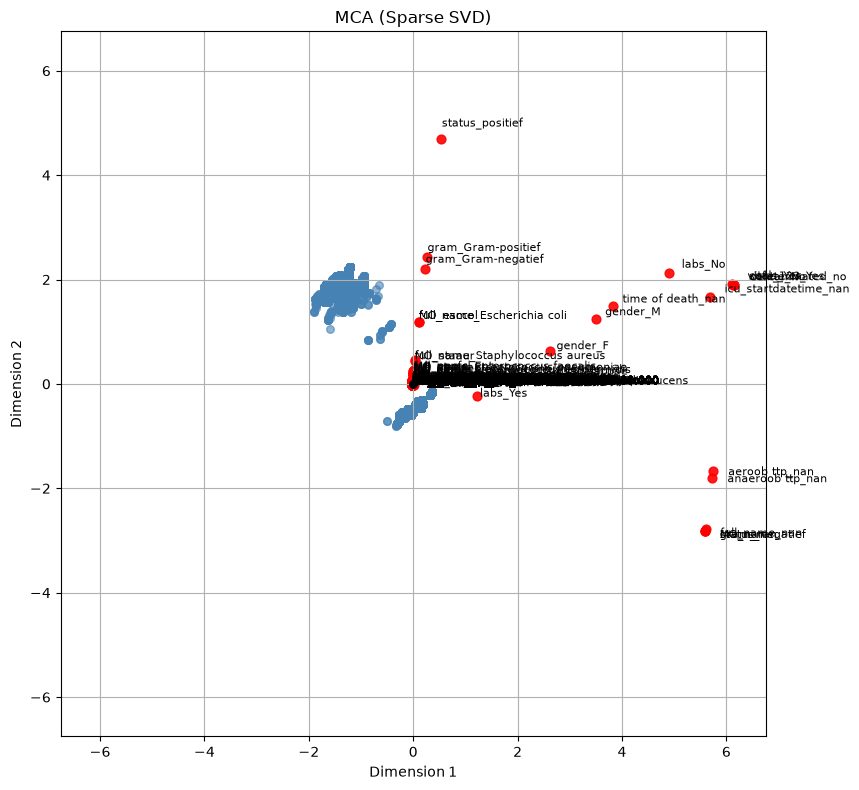

In [115]:
fig, ax = plt.subplots(figsize=(10, 8))

# Observations (points)
ax.scatter(row_coords[:, 0], row_coords[:, 1],
           s=30, alpha=0.6, color='steelblue', label='Observations')

# Category arrows (quiver from origin)
for i in range(col_coords.shape[0]):
    ax.scatter(
              col_coords[i, 0], col_coords[i, 1],
              s=40, color='red', alpha=0.9, label='categories')

# Label the arrows
feature_names = enc.get_feature_names_out(cat_columns)
for i, name in enumerate(feature_names):
    ax.text(col_coords[i, 0] * 1.05,
            col_coords[i, 1] * 1.05,
            name, color='black', fontsize=8)

# Origin marker
ax.scatter([0], [0], color='black', s=30, zorder=5)

# Axis limits symmetric around zero
max_abs = np.max(np.abs(np.vstack([row_coords, col_coords])))
lim     = max_abs * 1.10          # a little padding
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel('Dimension 1')
ax.set_ylabel('Dimension 2')
ax.set_title('MCA (Sparse SVD)')
ax.grid(True)
ax.set_aspect('equal')            # keep the shape true

plt.tight_layout()
plt.show()

***PCA***

C:\Users\DoumaB\AppData\Local\Temp\ipykernel_16968\41462664.py:16: DtypeWarning: Columns (17: aeroob ttp, 18: anaeroob ttp) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('dataframe_grams_antibiotic.csv')


Index(['SpecimenId_NL_CM_13_1_15', 'AGE', 'death', 'FLO_6', 'FLO_9',
       'SOFAscore_24h_total', 'SOFAscore_48h_total', 'SOFAscore_72h_total',
       'lab_bg_Lact', 'lab_chem_CRP', 'lab_chem_Creat', 'lab_hemat_Lymp',
       'lab_hemat_Neut', 'lab_hemat_WBC', 'LOS', 'event'],
      dtype='str')
Explained variance ratio: [0.1704531  0.12168441 0.0994576  0.08073098 0.07315653 0.07247863
 0.06542576 0.06318669 0.05092516 0.0498918  0.04800867 0.03208762
 0.02836889 0.02645569 0.01768846 0.        ]
Confusion matrix:
 [[  1  30   0]
 [  1 417  12]
 [  0  76   6]]


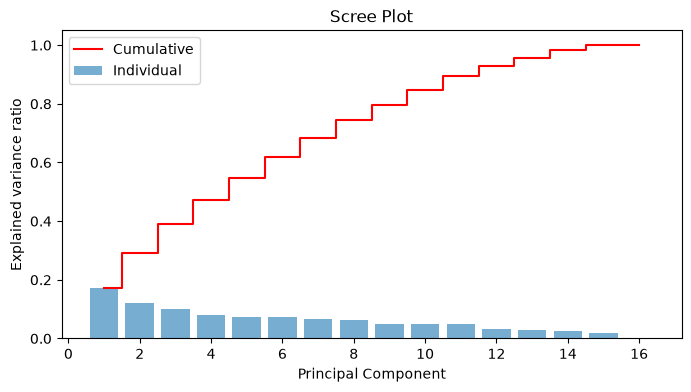

In [116]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ------------------------------------------------------------------
# 1. Load data & separate features / target
# ------------------------------------------------------------------
df = pd.read_csv('dataframe_grams_antibiotic.csv')

# Features: all numeric columns *except* the target column
X = df.select_dtypes(include='number').drop(columns=['event_status'], errors='ignore')
y_raw = df['event_status']          # <-- this is the string label

# ------------------------------------------------------------------
# 2. Encode the target (0 / 1)
# ------------------------------------------------------------------
le = LabelEncoder()
y = le.fit_transform(y_raw)   # 0 for 'negatief', 1 for 'positief'

# ------------------------------------------------------------------
# 3. Drop rows that have missing numeric values (or impute if you prefer)
# ------------------------------------------------------------------
X = X.dropna()
y = y[X.index]          # keep the target aligned with dropped rows

# ------------------------------------------------------------------
# 4. Train / test split
# ------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=0,
    stratify=y            # keeps class balance in both sets
)

# ------------------------------------------------------------------
# 5. Standardise the features
# ------------------------------------------------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# ------------------------------------------------------------------
# 6. PCA – keep two components (you can change n_components if you like)
# ------------------------------------------------------------------
pca = PCA(n_components=16, random_state=0)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca  = pca.transform(X_test_scaled)

print(X.columns)
print(f"Explained variance ratio: {pca.explained_variance_ratio_}")

# ------------------------------------------------------------------
# 7. Logistic Regression
# ------------------------------------------------------------------
clf = LogisticRegression(random_state=0, max_iter=200)
clf.fit(X_train_pca, y_train)

y_pred = clf.predict(X_test_pca)
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

# ------------------------------------------------------------------
# 8. Plot decision boundary on the *training* set (PC1 vs PC2)
# ------------------------------------------------------------------
X_set, y_set = X_train_pca, y_train

# Create a meshgrid
x1_min, x1_max = X_set[:,0].min()-1, X_set[:,0].max()+1
x2_min, x2_max = X_set[:,1].min()-1, X_set[:,1].max()+1
xx1, xx2 = np.meshgrid(
    np.arange(x1_min, x1_max, 0.01),
    np.arange(x2_min, x2_max, 0.01)
)

# # Predict on the grid
# Z = clf.predict(np.c_[xx1.ravel(), xx2.ravel()]).reshape(xx1.shape)

# plt.figure(figsize=(12,10))
# cmap_plot = ListedColormap(('yellow', 'white', 'aquamarine'))
# plt.contourf(xx1, xx2, Z, alpha=0.75, cmap=cmap_plot)

# # Scatter the training points
# colors = ['red', 'green', 'blue']   # enough for 3 classes; adjust if needed
# for idx, cls in enumerate(np.unique(y_set)):
#     plt.scatter(
#         X_set[y_set==cls, 0], X_set[y_set==cls, 1],
#         color=colors[idx % len(colors)],
#         label=le.classes_[cls]
#     )

# plt.title('Logistic Regression (Training set) – PCA space')
# plt.xlabel('PC1')
# plt.ylabel('PC2')
# plt.legend()
# plt.show()

evr = pca.explained_variance_ratio_
cum_evr = np.cumsum(evr)

plt.figure(figsize=(8,4))
plt.bar(range(1, len(evr)+1), evr, alpha=0.6, label='Individual')
plt.step(range(1, len(cum_evr)+1), cum_evr, where='mid',
         color='red', label='Cumulative')
plt.xlabel('Principal Component')
plt.ylabel('Explained variance ratio')
plt.title('Scree Plot')
plt.legend()
plt.show()
